# EDA on the original (official) data
Exploratory data analysis of the R2 returns data, with the findings collected in the last section.

**Questions**
1. What separates abusive returns from genuine ones?
2. Which signals are strong, which are weak, and which are traps?
3. Does the test period look like the training period?
4. Are some customer groups at risk of being treated unfairly?
5. Which products drive fit-related returns?

Needs only pandas, numpy and matplotlib. Put the five CSVs in a `data/` folder next to this notebook.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40, "display.width", 150, "display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (7, 3.4), "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = next(
    p for p in map(Path, ["data", "../data", "../FULL_CODE/data"]) if (p / "return_requests_train.csv").exists()
)
train = pd.read_csv(
    DATA_DIR / "return_requests_train.csv", parse_dates=["order_date", "delivery_date", "return_request_date"]
)
test = pd.read_csv(
    DATA_DIR / "return_requests_test.csv", parse_dates=["order_date", "delivery_date", "return_request_date"]
)
products = pd.read_csv(DATA_DIR / "products.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv", parse_dates=["signup_date"])
train["abusive"] = (train["label"] == "abusive").astype(int)
BASE = train["abusive"].mean()
print(f"train {train.shape}, test {test.shape}, base abuse rate {BASE:.3%}")


def abuse_by(group, min_rows: int = 1) -> pd.DataFrame:
    """Abusive share, row count and lift over the base rate for each group."""
    table = train.groupby(group, observed=True)["abusive"].agg(abuse_rate="mean", rows="size")
    table["lift"] = table["abuse_rate"] / BASE
    return table[table["rows"] >= min_rows].round(3)


def bar_rate(table: pd.DataFrame, title: str) -> None:
    ax = table["abuse_rate"].plot.bar(color="#4c78a8", title=title, rot=30)
    ax.axhline(BASE, color="#e45756", ls="--", lw=1, label=f"base rate {BASE:.1%}")
    ax.set_ylabel("abusive share")
    ax.legend()
    plt.tight_layout()
    plt.show()

train (43068, 24), test (16932, 22), base abuse rate 7.804%


## 1. The target
Abusive returns are rare, so any useful metric must be about *cost* or *ranking*, not accuracy.

,rows,share
label,,
genuine_fit_issue,20721,0.481
genuine_quality_issue,12059,0.280
genuine_wrong_item,6927,0.161
abusive,3361,0.078


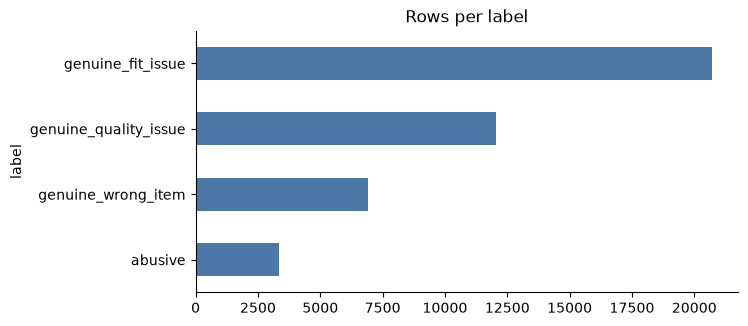

A model that approves everything is 92.2% "accurate" and catches nothing.


In [2]:
counts = train["label"].value_counts()
display(pd.DataFrame({"rows": counts, "share": (counts / len(train)).round(3)}))
counts.sort_values().plot.barh(color="#4c78a8", title="Rows per label")
plt.show()
print(f'A model that approves everything is {1 - BASE:.1%} "accurate" and catches nothing.')

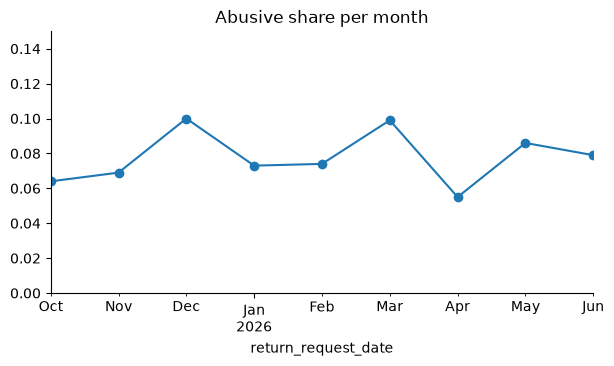

,abuse_rate,rows,lift
return_request_date,,,
2025-10,0.064,5194,0.824
2025-11,0.069,4744,0.889
2025-12,0.100,4994,1.283
2026-01,0.073,4719,0.934
2026-02,0.074,4394,0.951
2026-03,0.099,4961,1.268
2026-04,0.055,4547,0.702
2026-05,0.086,4747,1.104
2026-06,0.079,4768,1.019


In [3]:
monthly = abuse_by(train["return_request_date"].dt.to_period("M"))
monthly["abuse_rate"].plot(marker="o", ylim=(0, 0.15), title="Abusive share per month")
plt.show()
monthly

## 2. Timing: how long after delivery is the return requested?
Wardrobing (wear once, return) should show up as *late* returns.

,abuse_rate,rows,lift
days_since_delivery,,,
0-1,0.053,13411,0.681
2-3,0.033,6070,0.424
4-7,0.033,6823,0.421
8-14,0.062,6683,0.792
15-21,0.132,4996,1.688
22-30,0.227,5085,2.903


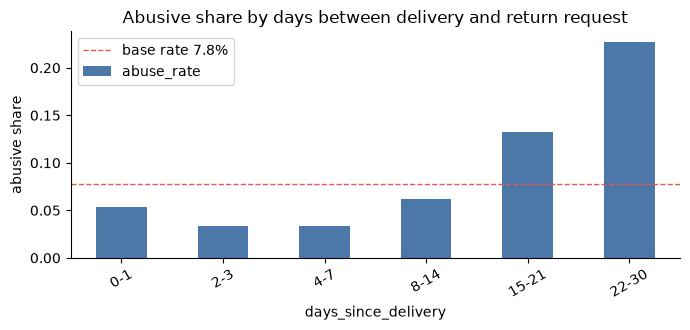

In [4]:
days = pd.cut(
    train["days_since_delivery"], [-1, 1, 3, 7, 14, 21, 30], labels=["0-1", "2-3", "4-7", "8-14", "15-21", "22-30"]
)
t = abuse_by(days)
display(t)
bar_rate(t, "Abusive share by days between delivery and return request")

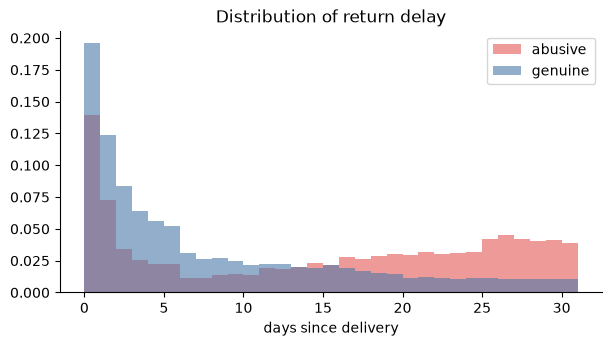

           count  mean   std  min  25%   50%   75%   max
abusive                                                 
0        39707.0   7.5   8.3  0.0  1.0   4.0  12.0  30.0
1         3361.0  14.5  10.6  0.0  3.0  16.0  24.0  30.0


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for label, colour in [("abusive", "#e45756"), ("genuine", "#4c78a8")]:
    values = train.loc[(train["abusive"] == 1) == (label == "abusive"), "days_since_delivery"]
    ax.hist(values, bins=range(0, 32), alpha=0.6, density=True, label=label, color=colour)
ax.set_xlabel("days since delivery")
ax.legend()
ax.set_title("Distribution of return delay")
plt.show()
print(train.groupby("abusive")["days_since_delivery"].describe().round(1))

In [6]:
t = abuse_by(pd.cut(train["delivery_days"], [-1, 2, 4, 6, 9, 30]))
display(t)
print("Delivery speed is a weak signal compared with return delay.")

,abuse_rate,rows,lift
delivery_days,,,
"(-1, 2]",0.074,11603,0.952
"(2, 4]",0.080,18414,1.024
"(4, 6]",0.077,9410,0.986
"(6, 9]",0.083,3641,1.066


Delivery speed is a weak signal compared with return delay.


## 3. Money: order value, item price, discount

,abuse_rate,rows,lift
item_price_inr,,,
"(74.999, 400.0]",0.088,5497,1.128
"(400.0, 584.0]",0.057,5326,0.729
"(584.0, 749.0]",0.051,5388,0.659
"(749.0, 949.0]",0.038,5326,0.493
"(949.0, 1199.0]",0.040,5781,0.516
"(1199.0, 1574.0]",0.055,5035,0.702
"(1574.0, 2199.0]",0.101,5407,1.294
"(2199.0, 13899.0]",0.195,5308,2.503


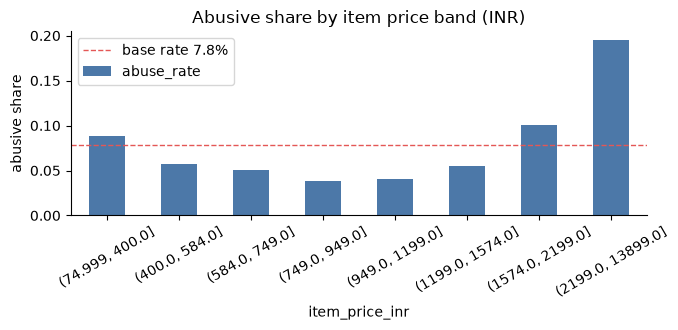

In [7]:
price_band = pd.qcut(train["item_price_inr"], 8, duplicates="drop")
t = abuse_by(price_band)
display(t)
bar_rate(t, "Abusive share by item price band (INR)")

,abuse_rate,rows,lift
discount_pct,,,
"(-1, 0]",0.076,7476,0.975
"(0, 10]",0.054,3032,0.689
"(10, 20]",0.062,6106,0.797
"(20, 30]",0.068,8401,0.872
"(30, 50]",0.083,13780,1.066
"(50, 90]",0.124,4273,1.592


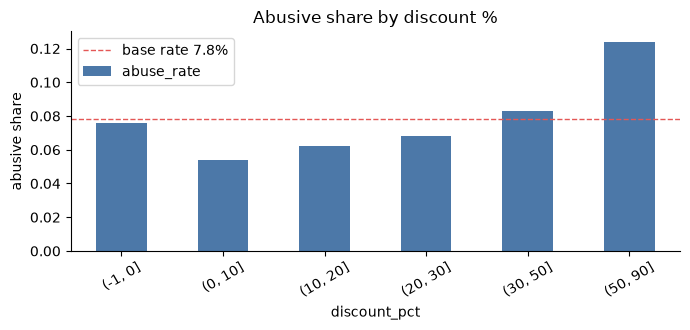

,abuse_rate,rows,lift
order_value_inr,,,
"(0.0, 500.0]",0.095,4445,1.217
"(500.0, 1000.0]",0.065,8764,0.829
"(1000.0, 2000.0]",0.073,12838,0.935
"(2000.0, 4000.0]",0.083,11322,1.070
"(4000.0, 8000.0]",0.083,4808,1.063
"(8000.0, 1000000.0]",0.102,891,1.309


In [8]:
t = abuse_by(pd.cut(train["discount_pct"], [-1, 0, 10, 20, 30, 50, 90]))
display(t)
bar_rate(t, "Abusive share by discount %")
value_band = pd.cut(train["order_value_inr"], [0, 500, 1000, 2000, 4000, 8000, 1e6])
display(abuse_by(value_band))

## 4. Basket, payment, warehouse, category

In [9]:
display(abuse_by(train["items_in_order"].clip(upper=5).rename("items_in_order (5 = 5+)")))
display(abuse_by("payment_method"))
display(abuse_by("fulfilment_centre"))

,abuse_rate,rows,lift
items_in_order (5 = 5+),,,
1,0.111,21639,1.427
2,0.046,13535,0.583
3,0.048,5307,0.616
4,0.034,2372,0.438
5,0.000,215,0.000


,abuse_rate,rows,lift
payment_method,,,
COD,0.106,16717,1.358
Card,0.058,7454,0.746
NetBanking,0.055,3037,0.709
UPI,0.063,13167,0.801
Wallet,0.061,2693,0.780


,abuse_rate,rows,lift
fulfilment_centre,,,
FC-BLR-1,0.076,9512,0.979
FC-DEL-1,0.078,13108,0.997
FC-HYD-1,0.076,5142,0.974
FC-KOL-1,0.074,5466,0.954
FC-MUM-1,0.083,9840,1.063


,abuse_rate,rows,lift
category,,,
Men Western,0.052,9121,0.663
Women Western,0.053,7492,0.676
Footwear,0.070,5510,0.902
Women Ethnic,0.084,17173,1.079
Men Ethnic,0.175,3772,2.242


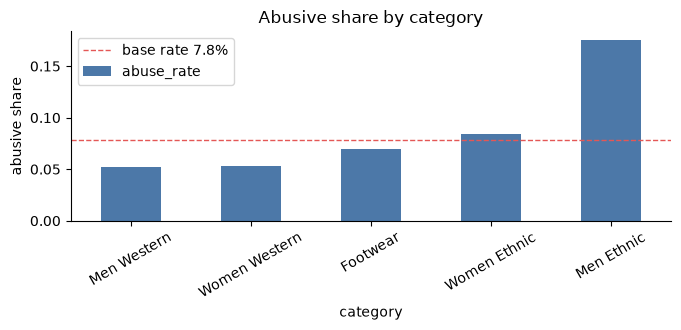

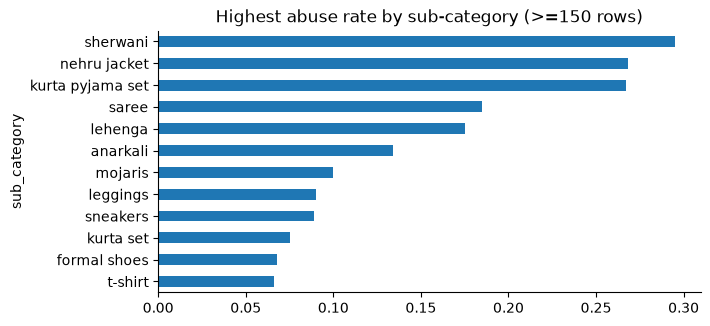

,abuse_rate,rows,lift
sub_category,,,
anarkali,0.134,1421,1.722
lehenga,0.175,921,2.240
saree,0.185,2764,2.374
kurta pyjama set,0.267,1362,3.415
nehru jacket,0.268,433,3.433
sherwani,0.295,420,3.783


In [10]:
t = abuse_by("category").sort_values("abuse_rate")
display(t)
bar_rate(t, "Abusive share by category")
sub = abuse_by("sub_category", min_rows=150).sort_values("abuse_rate")
sub["abuse_rate"].tail(12).plot.barh(title="Highest abuse rate by sub-category (>=150 rows)")
plt.show()
sub.tail(6)

## 5. The product catalogue

In [11]:
catalogue = train.merge(
    products[["product_id", "brand", "fabric", "fit_type", "price_inr"]], on="product_id", how="left"
)
catalogue["mrp_ratio"] = catalogue["item_price_inr"] / catalogue["price_inr"]
display(catalogue.groupby("fit_type")["abusive"].agg(["mean", "size"]).round(3).sort_values("mean"))
display(catalogue.groupby("fabric")["abusive"].agg(["mean", "size"]).round(3).sort_values("mean").tail(6))
print("item_price / catalogue price (should be <= 1 after discount):")
print(catalogue["mrp_ratio"].describe().round(3).to_string())

,mean,size
fit_type,,
tapered,0.022,1039
wide leg,0.026,233
skinny,0.031,450
mom fit,0.037,587
A-line,0.048,2529
fit and flare,0.051,393
bodycon,0.053,565
boxy,0.058,1020
churidar,0.065,138


,mean,size
fabric,,
organza,0.184,315
jacquard,0.192,939
chiffon,0.198,389
art silk,0.215,502
velvet,0.278,510
jacquard silk blend,0.316,95


item_price / catalogue price (should be <= 1 after discount):
count    43068.000
mean         0.723
std          0.189
min          0.250
25%          0.599
50%          0.700
75%          0.850
max          1.000


## 6. The customer
Repeat behaviour is the richest evidence a retailer has.

In [12]:
t = abuse_by(pd.cut(train["prior_return_rate"], [-0.01, 0.1, 0.25, 0.5, 0.75, 1.0]))
display(t)
first_order = train["prior_return_rate"].isna()
print(
    f"first-order customers (no history): abuse {train.loc[first_order, 'abusive'].mean():.3f} "
    f"vs others {train.loc[~first_order, 'abusive'].mean():.3f}"
)
display(abuse_by(pd.cut(train["customer_tenure_days"], [-1, 30, 90, 180, 365, 730, 5000])))
display(abuse_by(pd.cut(train["prior_orders_count"], [-1, 0, 2, 5, 10, 20, 500])))

,abuse_rate,rows,lift
prior_return_rate,,,
"(-0.01, 0.1]",0.063,6367,0.807
"(0.1, 0.25]",0.042,7465,0.544
"(0.25, 0.5]",0.061,14927,0.778
"(0.5, 0.75]",0.127,6453,1.632
"(0.75, 1.0]",0.154,4099,1.976


first-order customers (no history): abuse 0.075 vs others 0.078


,abuse_rate,rows,lift
customer_tenure_days,,,
"(-1, 30]",0.033,3294,0.428
"(30, 90]",0.094,3166,1.206
"(90, 180]",0.091,3998,1.167
"(180, 365]",0.078,7668,0.999
"(365, 730]",0.085,12035,1.087
"(730, 5000]",0.075,12907,0.963


,abuse_rate,rows,lift
prior_orders_count,,,
"(-1, 0]",0.075,3757,0.965
"(0, 2]",0.093,7004,1.191
"(2, 5]",0.085,8434,1.083
"(5, 10]",0.073,9005,0.933
"(10, 20]",0.066,8272,0.850
"(20, 500]",0.077,6596,0.989


In [13]:
per_customer = train.groupby("customer_id")["abusive"].agg(abusive_returns="sum", returns="size")
print("customers in train:", len(per_customer))
print("customers with at least one abusive return:", int((per_customer["abusive_returns"] > 0).sum()))
repeat = per_customer[per_customer["abusive_returns"] >= 3]
print(
    f"customers with >=3 abusive returns: {len(repeat)} -> {repeat['abusive_returns'].sum() / train['abusive'].sum():.1%} of all abusive returns"
)
display(
    per_customer.groupby(per_customer["returns"].clip(upper=8))["abusive_returns"]
    .agg(["mean", "size"])
    .round(3)
    .rename(columns={"mean": "avg abusive returns per customer", "size": "customers"})
)

customers in train: 17196
customers with at least one abusive return: 1775
customers with >=3 abusive returns: 324 -> 48.8% of all abusive returns


,avg abusive returns per customer,customers
returns,,
1,0.073,6465
2,0.133,4684
3,0.184,2555
4,0.274,1425
5,0.370,799
6,0.460,467
7,0.566,297
8,1.440,504


In [14]:
# Does an earlier abusive return predict the next one? (strictly earlier rows only)
ordered = train.sort_values(["customer_id", "return_request_date", "return_id"]).copy()
ordered["earlier_abusive"] = ordered.groupby("customer_id")["abusive"].cumsum() - ordered["abusive"]
ordered["earlier_returns"] = ordered.groupby("customer_id").cumcount()
display(ordered.groupby(ordered["earlier_abusive"].clip(upper=3))["abusive"].agg(["mean", "size"]).round(3))
display(ordered.groupby(ordered["earlier_returns"].clip(upper=6))["abusive"].agg(["mean", "size"]).round(3))

,mean,size
earlier_abusive,,
0,0.044,40395
1,0.438,1355
2,0.735,441
3,0.762,877


,mean,size
earlier_returns,,
0,0.066,17196
1,0.072,10731
2,0.077,6047
3,0.084,3492
4,0.096,2067
5,0.104,1268
6,0.163,2267


In [15]:
extra = train.merge(customers, on="customer_id", how="left")
display(extra.groupby("city_tier")["abusive"].agg(["mean", "size"]).round(3))
gap = (extra["order_date"] - extra["signup_date"]).dt.days
print("order date minus signup date (days):")
print(gap.describe().round(0).to_string())

,mean,size
city_tier,,
1,0.079,18503
2,0.072,14528
3,0.084,10037


order date minus signup date (days):
count    43068.0
mean       579.0
std        532.0
min          0.0
25%        176.0
50%        435.0
75%        820.0
max       2690.0


## 7. Interactions
Signals rarely act alone.

In [16]:
late = train["days_since_delivery"] > 14
cod = train["payment_method"] == "COD"
single = train["items_in_order"] == 1
grid = train.assign(
    late=late.map({True: "late (>14d)", False: "on time"}), cod=cod.map({True: "COD", False: "prepaid"})
)
pivot = grid.pivot_table(index="late", columns="cod", values="abusive", aggfunc="mean").round(3)
display(pivot)
count = grid.pivot_table(index="late", columns="cod", values="abusive", aggfunc="size")
display(count)
risky = late & cod & single
print(
    f"late + COD + single item: {risky.sum():,} rows, abuse rate {train.loc[risky, 'abusive'].mean():.3f} (base {BASE:.3f})"
)

cod,COD,prepaid
late,,
late (>14d),0.226,0.146
on time,0.066,0.036


cod,COD,prepaid
late,,
late (>14d),4213,5868
on time,12504,20483


late + COD + single item: 2,535 rows, abuse rate 0.275 (base 0.078)


## 8. The reason text
English, Hinglish and Hindi in Latin script, with typos and emoji.

In [17]:
for label in train["label"].unique():
    print(f"--- {label}")
    for text in train.loc[train["label"] == label, "customer_reason"].sample(4, random_state=3):
        print("   ", text)

--- genuine_fit_issue
    hello support, ordered it for a family wedding. don't like the product. kindly arrange pickup.
    theek se fit nahi hua, kripya wapas le lijiye, shukriya
    Jeans bhut loose he, Bhut loose fitting he, boyd pe shape hi nahi aa raha, Thanks in advance 😐
    Size bada pad gaya ek size down bhej do - Baaki order theek tha - Pese wapas kar do please
--- genuine_wrong_item


    hi team, Received an empty packet, no product insideeee. I have the unboxing video.
    Order adhoora aya hai, kuch cheez missing hai - Please isko solve karo
    wrong item received
    galat product
--- genuine_quality_issue
    seam open 😡👎
    Quality bilkul achhi nahin h. 559 rupaye diye the. doosra bhejh do. bahut niraasha hui.
    namaskar,, photo mein kuch aur dikhaya, bheja kuch aur, paise wapas chahiye
    Zip broke on the first day. Kindly do the needful. Worst experience eger...
--- abusive
    Size issue Want a refund
    Hello, Small holes are there in the fabric.
    Theek se fit nahin hua
    cloth is very thin and transparent. Totally waste of money.


In [18]:
HINDI = set(
    "hai hain nahi nhi nahin bahut bohot mein ka ki ke ko se pe tha thi hua hui gaya gayi aaya raha rahi kar karo diya kiya "
    "liya mila chahiye wapas mujhe mera meri maine hoon bhi bilkul kharab bekar kapda silai rang naap chhota chota bada dheela "
    "tang lambai jaisa sahi galat saman dabba khali paise theek zyada kuch abhi aur toh".split()
)


def non_english(text: str) -> bool:
    tokens = re.findall(r"[a-z]+", str(text).lower())
    hits = sum(t in HINDI for t in tokens)
    return bool(tokens) and hits >= 1 and hits / len(tokens) >= 0.12


train["non_english"] = train["customer_reason"].map(non_english)
test["non_english"] = test["customer_reason"].map(non_english)
train["n_words"] = train["customer_reason"].str.split().str.len()
train["has_emoji"] = train["customer_reason"].str.contains(r"[^\x00-\x7F]", regex=True)
print(f"rough non-English share: train {train['non_english'].mean():.1%}, test {test['non_english'].mean():.1%}")
display(train.groupby("label")[["non_english", "n_words", "has_emoji"]].mean().round(3))

rough non-English share: train 44.4%, test 45.3%


,non_english,n_words,has_emoji
label,,,
abusive,0.453,11.407,0.109
genuine_fit_issue,0.454,11.821,0.126
genuine_quality_issue,0.424,11.448,0.123
genuine_wrong_item,0.444,11.340,0.130


In [19]:
PATTERNS = {
    "empty box": r"empty|khali|khaali",
    "tags intact / unused": r"tag.{0,12}(?:intact|on)|unused|never worn|not worn|unwashed|sealed",
    "fit too small": r"too small|tight|chhota|chota|tang|kasa|small",
    "fit too large": r"too (?:big|large|loose)|loose|baggy|dheela|dhila|bada",
    "wrong item": r"wrong|galat|different|another|not what i ordered|nahi mangaya|doosra|dusra",
    "damage / defect": r"tor[en]|damag|defect|hole|stain|broken|phat|toot|daag|kharab",
    "colour mismatch": r"colou?r|rang",
    "not as described": r"not as (?:described|shown)|photo|picture|fake|duplicate|nakli",
    "wedding / occasion": r"wedding|shaadi|function|party|event|occasion",
    "refund demand only": r"refund|paisa|paise|wapas",
}
reasons = train["customer_reason"].fillna("").str.lower()
flags = pd.DataFrame({name: reasons.str.contains(rx, regex=True) for name, rx in PATTERNS.items()})
by_label = flags.groupby(train["label"]).mean().T.round(3)
by_label["abuse_rate_when_present"] = [train.loc[flags[c], "abusive"].mean().round(3) for c in by_label.index]
by_label

label,abusive,genuine_fit_issue,genuine_quality_issue,genuine_wrong_item,abuse_rate_when_present
empty box,0.027,0.001,0.000,0.032,0.280
tags intact / unused,0.020,0.032,0.006,0.019,0.070
fit too small,0.099,0.307,0.003,0.000,0.049
fit too large,0.043,0.176,0.020,0.000,0.036
wrong item,0.100,0.046,0.046,0.408,0.072
damage / defect,0.080,0.012,0.152,0.033,0.105
colour mismatch,0.131,0.054,0.185,0.200,0.085
not as described,0.126,0.019,0.148,0.015,0.156
wedding / occasion,0.109,0.075,0.089,0.089,0.102
refund demand only,0.150,0.112,0.157,0.112,0.092


In [20]:
# Words most over-represented in abusive text (log-odds, add-one smoothing)
tokens = reasons.str.findall(r"[a-z]{3,}")
abusive_counts = pd.Series([w for ws in tokens[train["abusive"] == 1] for w in set(ws)]).value_counts()
genuine_counts = pd.Series([w for ws in tokens[train["abusive"] == 0] for w in set(ws)]).value_counts()
vocab = pd.concat([abusive_counts, genuine_counts], axis=1, keys=["abusive", "genuine"]).fillna(0)
vocab = vocab[(vocab.sum(axis=1) >= 40)]
n_abusive, n_genuine = int(train["abusive"].sum()), int((1 - train["abusive"]).sum())
vocab["log_odds"] = np.log((vocab["abusive"] + 1) / n_abusive) - np.log((vocab["genuine"] + 1) / n_genuine)
display(vocab.sort_values("log_odds", ascending=False).head(12).round(2))
display(vocab.sort_values("log_odds").head(8).round(2))

,abusive,genuine,log_odds
bekar,21.0,44.0,1.75
empty,52.0,122.0,1.63
khali,31.0,77.0,1.58
dabba,19.0,48.0,1.57
sherwani,11.0,29.0,1.55
farak,22.0,60.0,1.49
waisa,22.0,62.0,1.46
bright,13.0,39.0,1.42
sikud,10.0,32.0,1.37
hot,13.0,43.0,1.32


,abusive,genuine,log_odds
extra,0.0,587.0,-3.91
returning,0.0,560.0,-3.86
sure,0.0,437.0,-3.61
that,0.0,261.0,-3.10
multiple,0.0,252.0,-3.06
took,0.0,230.0,-2.97
mangaye,0.0,222.0,-2.94
isliye,0.0,194.0,-2.80


In [21]:
# Does a customer reuse the exact same reason text?
key = train["customer_reason"].str.lower().str.strip()
repeat_text = train.assign(key=key).groupby(["customer_id", "key"])["abusive"].transform("size") > 1
print(f"rows whose exact reason text repeats within the same customer: {repeat_text.mean():.1%}")
print(
    f"abuse rate when repeated: {train.loc[repeat_text, 'abusive'].mean():.3f}   otherwise: {train.loc[~repeat_text, 'abusive'].mean():.3f}"
)

rows whose exact reason text repeats within the same customer: 2.9%
abuse rate when repeated: 0.321   otherwise: 0.071


**Reading:** text separates the three *genuine* reasons well, but abusers copy genuine wording, so wording is weak evidence of abuse by itself. Text is most useful as a *consistency* check against the order facts and the customer's history.

## 9. Fairness groups: base rates
The scorer compares how often **genuine** customers of each group get flagged.

In [22]:
groups = {
    "new customer (<90 days)": train["customer_tenure_days"] < 90,
    "low value order (<1000 INR)": train["order_value_inr"] < 1000,
    "non-English reason (rough guess)": train["non_english"],
}
rows = []
for name, mask in groups.items():
    rows.append(
        {
            "group": name,
            "rows": int(mask.sum()),
            "abuse_rate_in_group": train.loc[mask, "abusive"].mean(),
            "abuse_rate_others": train.loc[~mask, "abusive"].mean(),
        }
    )
fair = pd.DataFrame(rows).set_index("group").round(3)
fair["ratio"] = (fair["abuse_rate_in_group"] / fair["abuse_rate_others"]).round(2)
fair

,rows,abuse_rate_in_group,abuse_rate_others,ratio
group,,,,
new customer (<90 days),6411,0.063,0.081,0.78
low value order (<1000 INR),13123,0.075,0.080,0.94
non-English reason (rough guess),19127,0.080,0.077,1.04


In [23]:
# Which risk signals do the fairness groups carry? (a proxy check)
signals = pd.DataFrame(
    {
        "late (>14d)": late,
        "COD": cod,
        "single item": single,
        "high prior return rate (>0.5)": train["prior_return_rate"] > 0.5,
    }
)
pd.concat({name: signals[mask].mean() for name, mask in groups.items()}, axis=1).round(3)

,new customer (<90 days),low value order (<1000 INR),non-English reason (rough guess)
late (>14d),0.204,0.234,0.241
COD,0.574,0.505,0.533
single item,0.503,0.850,0.508
high prior return rate (>0.5),0.155,0.241,0.256


**Reading:** abuse is about as common inside each group as outside it, so there is no legitimate reason to flag a group more often. If a group looks riskier to a model, it will be because of *proxy signals* (e.g. no history, small baskets), which is exactly what the table above checks.

## 10. Train vs test: does the future look like the past?

In [24]:
numeric = [
    "order_value_inr",
    "item_price_inr",
    "discount_pct",
    "days_since_delivery",
    "delivery_days",
    "items_in_order",
    "customer_tenure_days",
    "prior_orders_count",
    "prior_return_rate",
]
drift = pd.DataFrame({"train_mean": train[numeric].mean(), "test_mean": test[numeric].mean()})
drift["change_%"] = ((drift["test_mean"] / drift["train_mean"] - 1) * 100).round(1)
drift.round(2)

,train_mean,test_mean,change_%
order_value_inr,2188.35,2059.33,-5.9
item_price_inr,1291.96,1197.50,-7.3
discount_pct,27.72,31.87,15.0
days_since_delivery,8.08,8.41,4.0
delivery_days,3.77,3.73,-1.0
items_in_order,1.75,1.75,0.3
customer_tenure_days,590.88,655.06,10.9
prior_orders_count,11.08,12.88,16.2
prior_return_rate,0.39,0.41,4.2


In [25]:
def psi(a: pd.Series, b: pd.Series) -> float:
    p, q = a.value_counts(normalize=True), b.value_counts(normalize=True)
    idx = p.index.union(q.index)
    p, q = p.reindex(idx, fill_value=0) + 1e-4, q.reindex(idx, fill_value=0) + 1e-4
    return float(((p - q) * np.log(p / q)).sum())


cats = ["category", "payment_method", "fulfilment_centre", "size_ordered"]
print("population stability index (<0.1 = stable):")
print(pd.Series({c: psi(train[c], test[c]) for c in cats}).round(4).to_string())
display(
    pd.concat(
        [train["payment_method"].value_counts(normalize=True), test["payment_method"].value_counts(normalize=True)],
        axis=1,
        keys=["train", "test"],
    ).round(3)
)
new_in_test = set(test["product_id"]) - set(train["product_id"])
print(
    f"products only in test: {len(new_in_test)}  |  test rows from customers seen in train: {test['customer_id'].isin(train['customer_id']).mean():.1%}"
)

population stability index (<0.1 = stable):
category             0.0004
payment_method       0.0009
fulfilment_centre    0.0012
size_ordered         0.0032


,train,test
payment_method,,
COD,0.388,0.385
UPI,0.306,0.316
Card,0.173,0.165
NetBanking,0.071,0.069
Wallet,0.063,0.065


products only in test: 0  |  test rows from customers seen in train: 73.7%


## 11. Which single features rank requests best?
Univariate ranking power (AUC, 0.5 = useless) for numeric features, on the training data.

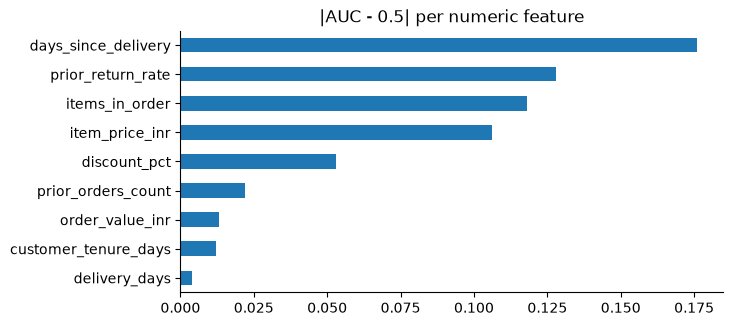

,AUC,strength
days_since_delivery,0.676,0.176
prior_return_rate,0.628,0.128
items_in_order,0.382,0.118
item_price_inr,0.606,0.106
discount_pct,0.553,0.053
prior_orders_count,0.478,0.022
order_value_inr,0.513,0.013
customer_tenure_days,0.512,0.012
delivery_days,0.504,0.004


In [26]:
def auc(score: pd.Series, target: pd.Series) -> float:
    data = pd.DataFrame({"s": score, "y": target}).dropna()
    ranks = data["s"].rank()
    n1, n0 = data["y"].sum(), (1 - data["y"]).sum()
    return float((ranks[data["y"] == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


ranked = pd.Series({c: auc(train[c], train["abusive"]) for c in numeric}).sort_values(ascending=False)
ranked = pd.DataFrame({"AUC": ranked.round(3), "strength": (ranked - 0.5).abs().round(3)}).sort_values(
    "strength", ascending=False
)
ranked["strength"].plot.barh(title="|AUC - 0.5| per numeric feature").invert_yaxis()
plt.show()
ranked

## 12. Fit-related returns by product (the size-chart question)

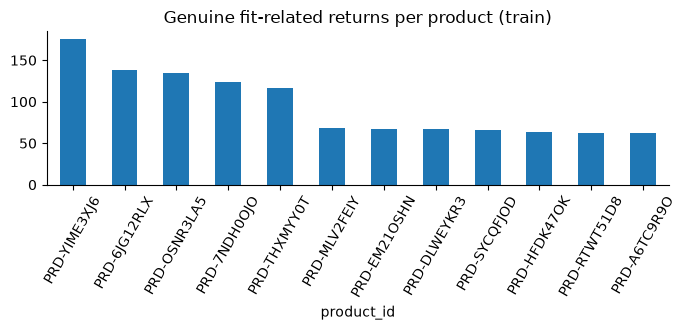

,fit_returns,title,category,sub_category,size_chart_id,all_returns,fit_share_of_returns
product_id,,,,,,,
PRD-YIME3XJ6,176,Gulmohar Threads Women's Lavender Ikat Print Straight Cotton Kurta,Women Ethnic,kurta,SC-7R3F11,205,0.86
PRD-6JG12RLX,138,Karonda Studio Women's Bottle Green Light Fade Mom Fit Cotton Denim Jeans,Women Western,jeans,SC-KJ9ASP,167,0.83
PRD-OSNR3LA5,135,Silvat Menswear Men's Black Light Fade Tapered Cotton Denim Jeans,Men Western,jeans,SC-20NXB1,157,0.86
PRD-7NDH0OJO,124,Silvat Menswear Men's Beige Solid Formal Slim Linen Blend Shirt,Men Western,shirt,SC-LX39AM,156,0.79
PRD-THXMYY0T,117,Gulmohar Threads Women's Rani Pink Georgette Embroidered Kurta Set,Women Ethnic,kurta set,SC-MVJ0Y9,157,0.75
PRD-MLV2FEIY,68,Gulmohar Threads Women's Black Solid A-Line Chanderi Silk Kurta,Women Ethnic,kurta,SC-YXAUMG,99,0.69
PRD-EM21OSHN,67,Silvat Menswear Men's Beige Clean Look Slim Stretchable Denim Jeans,Men Western,jeans,SC-977YA6,108,0.62
PRD-DLWEYKR3,67,Kesarbagh Women's Rani Pink Bandhani Print A-Line Rayon Kurta,Women Ethnic,kurta,SC-V6OFZ8,95,0.71


In [27]:
fit = train[train["label"] == "genuine_fit_issue"]
per_product = fit.groupby("product_id").size().sort_values(ascending=False)
top = per_product.head(12)
top.plot.bar(title="Genuine fit-related returns per product (train)", rot=60)
plt.tight_layout()
plt.show()
report = (
    top.head(8)
    .to_frame("fit_returns")
    .join(products.set_index("product_id")[["title", "category", "sub_category", "size_chart_id"]])
)
report["all_returns"] = train.groupby("product_id").size().reindex(report.index)
report["fit_share_of_returns"] = (report["fit_returns"] / report["all_returns"]).round(2)
report

In [28]:
small = fit["customer_reason"].str.contains(r"small|tight|chhota|chota|tang|kasa", case=False)
large = fit["customer_reason"].str.contains(r"large|big|loose|baggy|dheela|dhila|bada", case=False)
print(f"fit complaints: too small {small.mean():.0%}, too large {large.mean():.0%}")
print(
    "fit returns of ranks 1-5:",
    per_product.head(5).tolist(),
    "| rank 6:",
    int(per_product.iloc[5]),
    "| rank 7:",
    int(per_product.iloc[6]),
)
print("share of all fit returns held by the top 5 products:", f"{per_product.head(5).sum() / per_product.sum():.1%}")
by_sub = fit.groupby("sub_category").size().sort_values(ascending=False).head(6)
print(by_sub.to_string())

fit complaints: too small 31%, too large 21%
fit returns of ranks 1-5: [176, 138, 135, 124, 117] | rank 6: 68 | rank 7: 67
share of all fit returns held by the top 5 products: 3.3%
sub_category
kurta        4572
jeans        2984
kurta set    2082
top          1788
shirt        1627
t-shirt      1064


## 13. Findings

In [29]:
# Findings table, computed from the data above so the numbers cannot drift from the analysis
def rate(mask) -> float:
    return float(train.loc[mask, "abusive"].mean())


findings = pd.DataFrame(
    [
        ("return requested > 14 days after delivery", rate(late), int(late.sum())),
        (
            "return requested within 1 day of delivery",
            rate(train["days_since_delivery"] <= 1),
            int((train["days_since_delivery"] <= 1).sum()),
        ),
        ("cash on delivery", rate(cod), int(cod.sum())),
        ("prepaid (non-COD)", rate(~cod), int((~cod).sum())),
        ("single-item order", rate(single), int(single.sum())),
        ("2+ items in order", rate(~single), int((~single).sum())),
        ("discount above 50%", rate(train["discount_pct"] > 50), int((train["discount_pct"] > 50).sum())),
        (
            "Men Ethnic category",
            rate(train["category"] == "Men Ethnic"),
            int((train["category"] == "Men Ethnic").sum()),
        ),
        (
            "prior return rate > 0.5",
            rate(train["prior_return_rate"] > 0.5),
            int((train["prior_return_rate"] > 0.5).sum()),
        ),
        ("first-time customer (no history)", rate(first_order), int(first_order.sum())),
        (
            "customer tenure <= 30 days",
            rate(train["customer_tenure_days"] <= 30),
            int((train["customer_tenure_days"] <= 30).sum()),
        ),
        ("late + COD + single item", rate(risky), int(risky.sum())),
    ],
    columns=["segment", "abuse_rate", "rows"],
).set_index("segment")
findings["lift_vs_base"] = findings["abuse_rate"] / BASE
findings.round(3)

,abuse_rate,rows,lift_vs_base
segment,,,
return requested > 14 days after delivery,0.180,10081,2.301
return requested within 1 day of delivery,0.053,13411,0.681
cash on delivery,0.106,16717,1.358
prepaid (non-COD),0.060,26351,0.773
single-item order,0.111,21639,1.427
2+ items in order,0.044,21429,0.569
discount above 50%,0.124,4273,1.592
Men Ethnic category,0.175,3772,2.242
prior return rate > 0.5,0.138,10552,1.766


## Findings (numbers are from the tables above, training data, 43,068 returns, base abuse rate 7.8%)

### 1. The target
- 7.8% abusive, 48.1% fit, 28.0% quality, 16.1% wrong item. Approving everything is 92% "accurate" and catches nothing, so judge models by cost and ranking quality, never accuracy.
- The abusive share is **not constant**: it moves between 5.5% (April 2026) and 10.0% (December 2025), with peaks in December and March. A model must not assume one fixed rate, and calibration should be checked on recent months.

### 2. Strongest signals (what abusive returns look like)
| Signal | Abuse rate | Compared with 7.8% base |
|---|---|---|
| Return requested 22-30 days after delivery | 22.7% | 2.9x |
| Return requested 15-21 days after delivery | 13.2% | 1.7x |
| Return requested 2-7 days after delivery | 3.3% | 0.4x |
| Customer already has **one earlier abusive return** | 43.8% | 5.6x |
| Customer has two or more earlier abusive returns | 73.5-76.2% | about 9.5x |
| Same exact reason text reused by the same customer | 32.1% | 4.1x |
| Prior return rate above 0.75 | 15.4% | 2.0x |
| Late (>14 days) + cash on delivery + single item | 27.5% | 3.5x |
| Single-item order | 11.1% | 1.4x (multi-item orders: 3.4-4.8%) |
| Cash on delivery | 10.6% | 1.4x (prepaid: 5.5-6.3%) |
| Discount above 50% | 12.4% | 1.6x |
| Item price above 2,199 INR | 19.5% | 2.5x |
| Men Ethnic category | 17.5% | 2.2x (sherwani 29.5%, nehru jacket 26.8%, kurta pyjama set 26.7%) |
| Free size / semi-stitched items | 17.0% / 17.6% | 2.2x |
| Velvet / jacquard / art silk / chiffon fabrics | 19-28% | 2.5-3.6x |
| Reason text claims an empty box | 28.0% | 3.6x |

Customer history is the richest evidence: 324 customers with three or more abusive returns account for **48.8% of all abusive returns**, and customers with 8+ returns average 1.4 abusive returns each.

### 3. Weak signals and traps
- **Delivery speed, warehouse and city tier** barely move the abuse rate (7.2-8.4% across their levels).
- **Order value is not fraud evidence**: 7.5% below 1,000 INR vs 8.0% above. Item *price* matters at the extremes, but the pattern is U-shaped (cheapest band 8.8%, mid bands 4-5%, top band 19.5%).
- **New customers are not riskier.** Customers with 30 days or less of tenure are abusive only 3.3% of the time, and first-order customers (no history) 7.5%, about the base rate. Missing history must not be punished.
- Univariate ranking power (AUC, 0.5 = useless): days since delivery 0.68, prior return rate 0.63, price 0.61, discount 0.55, everything else about 0.5.
- **Text is weak evidence of abuse.** Language mix and length are identical across labels (non-English share 42-45% for every class). Abusers copy genuine wording ("size issue", "cloth is thin"). Text separates the *genuine reasons* well (e.g. "too small" in 31% of fit returns and only 10% of abusive ones), so it is best used to explain the genuine reason and to flag *inconsistencies*, not as a fraud detector.
- Some phrases occur only in genuine returns (e.g. "extra", "returning", "sure", "mangaye", "isliye" - zero abusive occurrences in hundreds of rows). These are strong "this is genuine" cues and suggest part of the genuine text follows templates.

### 4. Fairness
- Abuse base rates are close between groups: new customers 6.3% vs 8.1% others, low-value orders 7.5% vs 8.0%, non-English text 8.0% vs 7.7%. There is no legitimate reason to flag one group more often.
- **Proxy risk:** new customers use cash on delivery 57% of the time (all orders: 39%), and low-value orders are single-item 85% of the time (all orders: 50%). A model that leans on COD or single-item status can end up flagging these groups more often, even though the groups are not riskier. This must be measured, and fixed without flagging low-risk customers just to balance numbers.
- Language must not be a model input: it is a fairness group and could become a proxy.

### 5. Train vs test
- The test period (July-September 2026) follows the training period. Categorical mixes are stable (population stability index below 0.004), there are **no products that appear only in the test set**, and 73.7% of test requests come from customers who also appear in train.
- Mild shifts: discount +15% (27.7 to 31.9), prior orders +16%, tenure +11%, item price -7%. Nothing severe, but it argues for time-based validation and for checking calibration on the most recent months.

### 6. Fit returns and the size chart
- Five products clearly lead the genuine fit-return counts: **176, 138, 135, 124 and 117** returns. The sixth has 68 and the seventh 67, so the top 5 is well separated.
- They are two kurta/kurta-set items, two denim jeans and one formal shirt. Across all products, kurtas (4,572), jeans (2,984) and kurta sets (2,082) lead fit complaints.
- Fit complaints are 31% "too small", 21% "too large" and the rest unspecific.
- The data lists returns, not all orders, so a true fit-return *rate* per product cannot be computed; ranking is by volume of genuine fit returns.

### 7. What this means for modelling
1. Build **point-in-time customer history** (earlier returns, earlier outcomes, repeated reasons, return delay) - it carries most of the signal.
2. Use timing, payment, basket size, price, discount and category as supporting features; use text for the genuine reason and consistency checks.
3. Validate **by time** and group by customer, because customers recur across the split.
4. Calibrate probabilities on recent months, since the base rate drifts between 5.5% and 10%.
5. Audit fairness for new, low-value and non-English customers and avoid proxy-driven flagging.
